# **1. Mengimport library panda dan matplotlib. Koneksikan colab ke google drive**

In [10]:
import pandas as pd
from google.colab import drive
import matplotlib.pyplot as plt
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **2. Membaca lokasi file dataset yang sudah dibersihkan pada tugas data cleansing**

In [11]:
file_path = '/content/drive/MyDrive/Colab Notebooks/IMDB_dataset_clean.xlsx'
data = pd.read_excel(file_path, engine='openpyxl')

# **3. Test print data apakah sudah terkoneksi**

In [12]:
display(data.head())

,Title_ID,Original_Title,Release_Date,Genre,Duration,Country,Content Rating,Director,Income,Votes,Score,Release_Year,Score_Category
0,tt0111161,The Shawshank Redemption,1995-02-10,Drama,142.0,USA,R,Frank Darabont,2.881524e+07,2278845.0,9.3,1995.0,High
1,tt0068646,The Godfather,1972-09-21,"Crime, Drama",175.0,USA,R,Francis Ford Coppola,2.461210e+08,1572674.0,9.2,1972.0,High
2,tt0468569,The Dark Knight,2008-07-23,"Action, Crime, Drama",152.0,USA,PG-13,Christopher Nolan,1.005455e+09,2241615.0,9.0,2008.0,High
3,tt0071562,The Godfather: Part II,1975-09-25,"Crime, Drama",220.0,USA,R,Francis Ford Coppola,4.080358e+08,1098714.0,NaN,1975.0,Unknown
4,tt0110912,Pulp Fiction,1994-10-28,"Crime, Drama",129.5,USA,R,Quentin Tarantino,2.228318e+08,1780147.0,8.9,1994.0,High


# **4. Persiapan agregasi data total pendapatan film per sesuai tahun rilis**

In [23]:
dataset_income = data.groupby('Release_Year')['Income'].sum().reset_index()

dataset_income = dataset_income.dropna()
dataset_income = dataset_income.sort_values('Release_Year')

dataset_income['Income_in_Millions'] = dataset_income['Income'] / 1000000

print(dataset_income.head())

   Release_Year      Income  Income_in_Millions
0        1937.0    457688.0            0.457688
1        1945.0    969879.0            0.969879
2        1948.0   7724827.0            7.724827
3        1953.0   1864182.0            1.864182
4        1955.0  37354807.0           37.354807


# **5. Membuat Line Chart Trend Dasar**

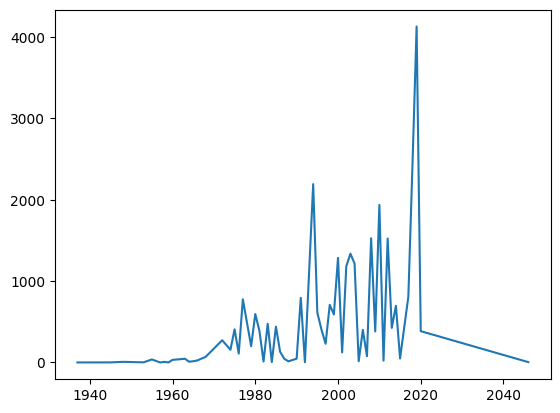

In [24]:
plt.plot(dataset_income['Release_Year'], dataset_income['Income_in_Millions'])
plt.show()

# **6. Mengubah Figure Size**

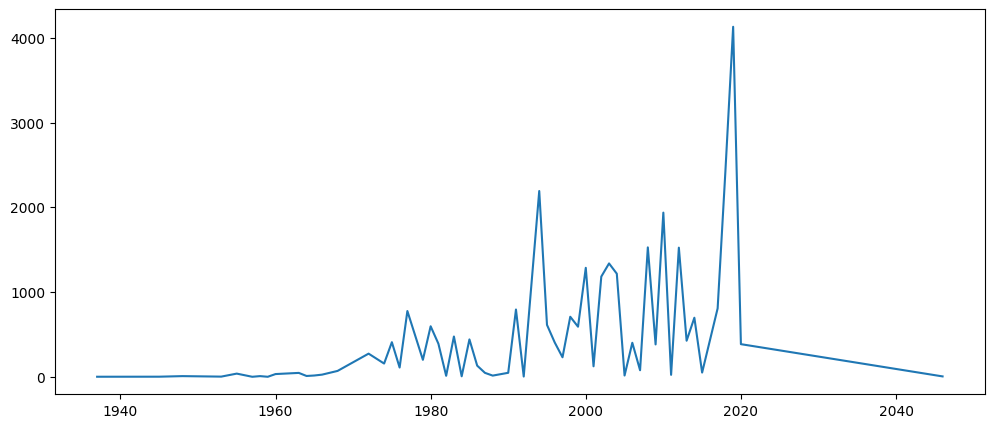

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(dataset_income['Release_Year'], dataset_income['Income_in_Millions'])
plt.show()

# **7. Menambahkan Title dan Axis Labels**

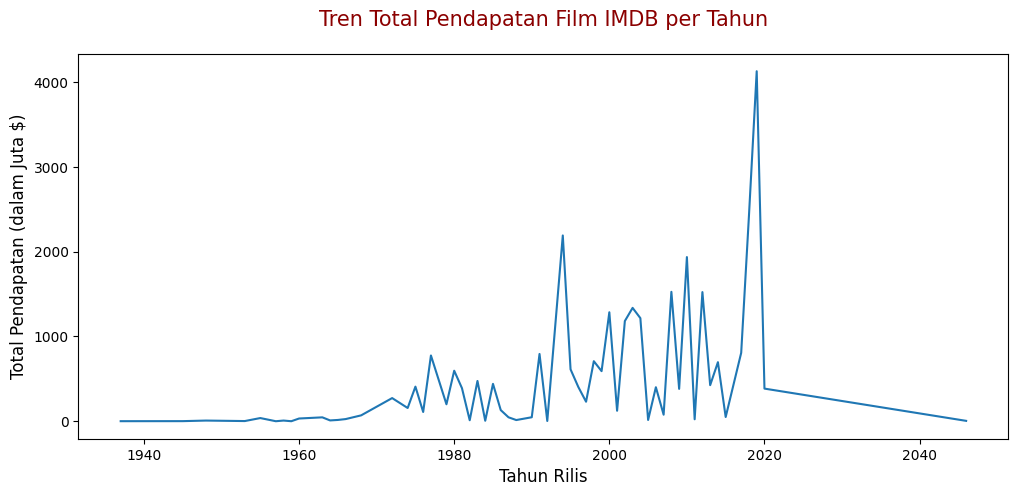

In [26]:
plt.figure(figsize=(12, 5))
plt.plot(dataset_income['Release_Year'], dataset_income['Income_in_Millions'])

# Menambahkan judul dan label sumbu
plt.title('Tren Total Pendapatan Film IMDB per Tahun', loc='center', pad=20, fontsize=15, color='darkred')
plt.xlabel('Tahun Rilis', fontsize=12)
plt.ylabel('Total Pendapatan (dalam Juta $)', fontsize=12)

plt.show()

# **8. Kustomisasi Line & Point**

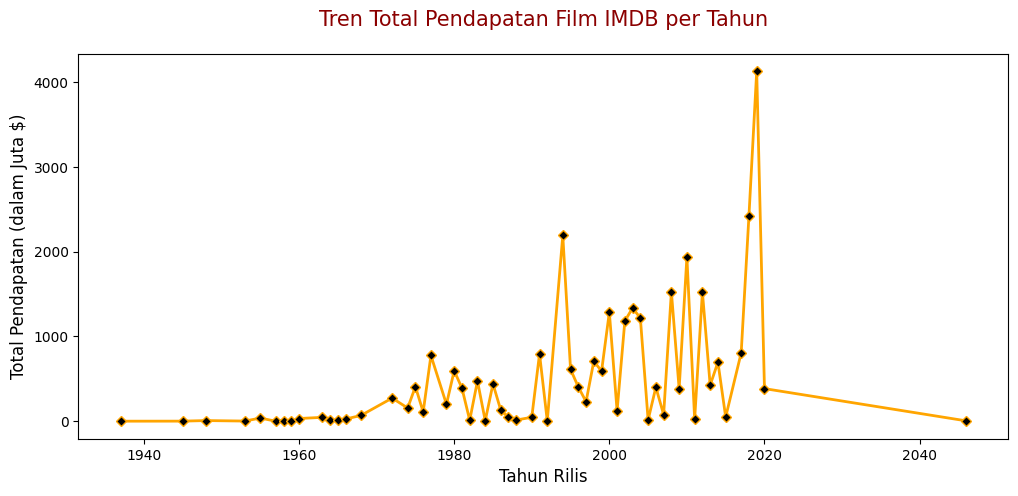

In [27]:
plt.figure(figsize=(12, 5))

# Kustomisasi garis (warna oranye) dan titik (bentuk wajik/diamond 'D')
plt.plot(dataset_income['Release_Year'], dataset_income['Income_in_Millions'],
         color='orange', linewidth=2, linestyle='-', marker='D', markersize=5, markerfacecolor='black')

plt.title('Tren Total Pendapatan Film IMDB per Tahun', loc='center', pad=20, fontsize=15, color='darkred')
plt.xlabel('Tahun Rilis', fontsize=12)
plt.ylabel('Total Pendapatan (dalam Juta $)', fontsize=12)

plt.show()

# **9. Kustomisasi pada Grid**

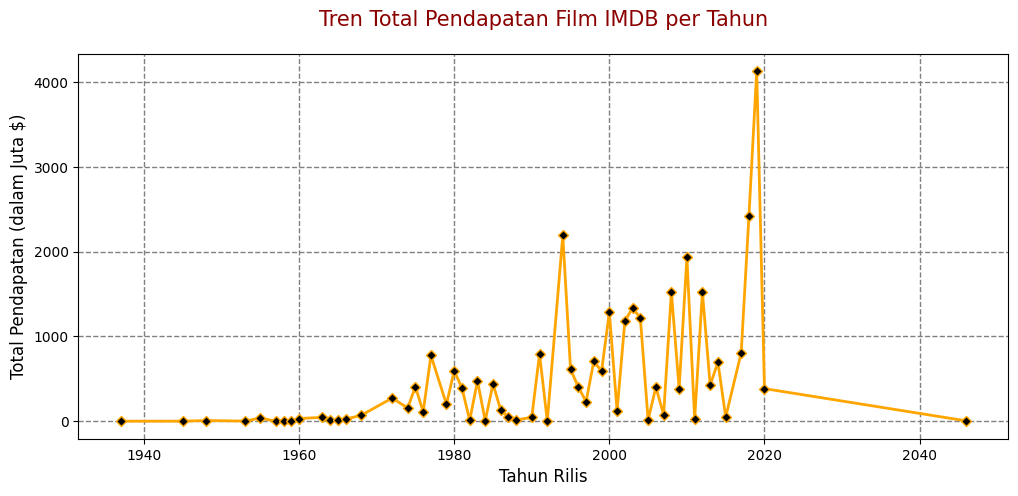

In [28]:
plt.figure(figsize=(12, 5))

plt.plot(dataset_income['Release_Year'], dataset_income['Income_in_Millions'],
         color='orange', linewidth=2, linestyle='-', marker='D', markersize=5, markerfacecolor='black')

plt.title('Tren Total Pendapatan Film IMDB per Tahun', loc='center', pad=20, fontsize=15, color='darkred')
plt.xlabel('Tahun Rilis', fontsize=12)
plt.ylabel('Total Pendapatan (dalam Juta $)', fontsize=12)

# Menambahkan gridline dengan gaya garis putus-putus
plt.grid(color='gray', linestyle='--', linewidth=1)

plt.show()

# **10. Menambahkan Informasi pada Plot (Hasil Akhir)**

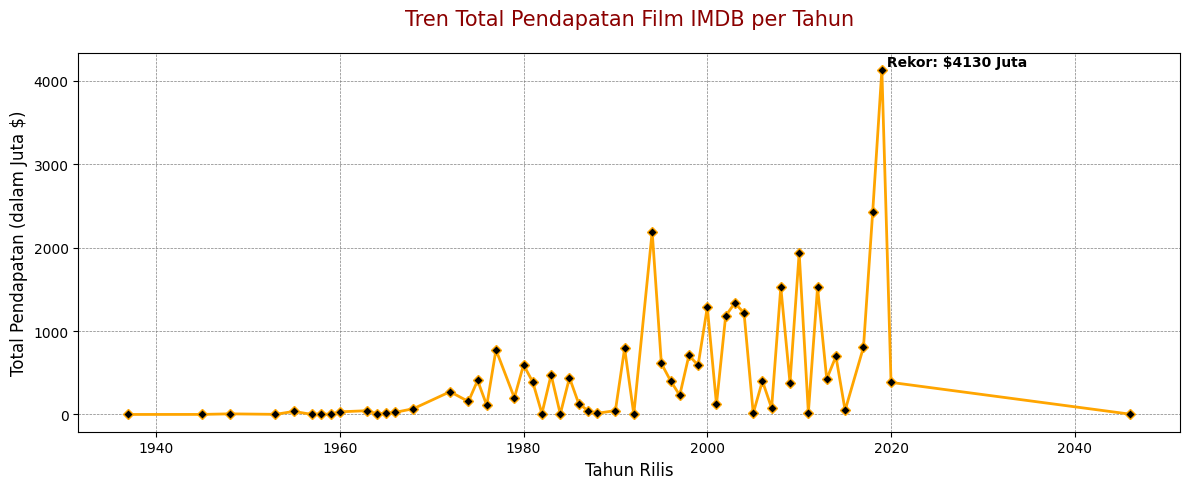

In [29]:
plt.figure(figsize=(12, 5))

plt.plot(dataset_income['Release_Year'], dataset_income['Income_in_Millions'],
         color='orange', linewidth=2, linestyle='-', marker='D', markersize=5, markerfacecolor='black')

plt.title('Tren Total Pendapatan Film IMDB per Tahun', loc='center', pad=20, fontsize=15, color='darkred')
plt.xlabel('Tahun Rilis', fontsize=12)
plt.ylabel('Total Pendapatan (dalam Juta $)', fontsize=12)
plt.grid(color='gray', linestyle='--', linewidth=0.5)

# Menambahkan anotasi (teks) pada tahun dengan pendapatan tertinggi
max_income_row = dataset_income.loc[dataset_income['Income_in_Millions'].idxmax()]
tahun_puncak = max_income_row['Release_Year']
pendapatan_puncak = max_income_row['Income_in_Millions']

plt.text(tahun_puncak, pendapatan_puncak + 50,
         f' Rekor: ${pendapatan_puncak:.0f} Juta',
         color='black', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()